In [ ]:
!pip install --quiet -U langchain-community langchain-experimental langchain_google_genai

In [ ]:
!pip --quiet install -U langchain-core langgraph langgraph-prebuilt

In [ ]:
from typing_extensions import TypedDict
from langchain_core.messages import AnyMessage
from typing import Annotated
from langgraph.graph.message import add_messages

### Build a Simple Workflow or Graph Using LangGraph

**State**
First, define the State of the graph.

The State schema serves as the input schema for all Nodes and Edges in the graph.

Let's use the TypedDict class from python's typing module as our schema, which provides type hints for the keys.

In [ ]:
from typing_extensions import TypedDict
class State(TypedDict):
    graph_info:str

**Nodes** :
Nodes are just python functions.

The first positional argument is the state, as defined above.

Because the state is a TypedDict with schema as defined above, each node can access the key, graph_state, with state['graph_state'].

Each node returns a new value of the state key graph_state.

By default, the new value returned by each node will override the prior state value.

In [ ]:
def start_play(state:State):
    print("Start_Play node has been called")
    return {"graph_info":state['graph_info'] + " I am planning to play"}

def cricket(state:State):
    print("My Cricket node has been called")
    return {"graph_info":state['graph_info'] + " Cricket"}

def badminton(state:State):
    print("My badminton node has been called")
    return {"graph_info":state['graph_info'] + " Badminton"}

In [ ]:
import random
from typing import Literal

def random_play(state:State)-> Literal['cricket','badminton']:
    graph_info=state['graph_info']

    if random.random()>0.5:
        return "cricket"
    else:
        return "badminton"

**Graph Construction**
Now, we build the graph from our components defined above.

The StateGraph class is the graph class that we can use.

First, we initialize a StateGraph with the State class we defined above.

Then, we add our nodes and edges.

We use the START Node, a special node that sends user input to the graph, to indicate where to start our graph.

The END Node is a special node that represents a terminal node.

Finally, we compile our graph to perform a few basic checks on the graph structure.

We can visualize the graph as a Mermaid diagram.

In [ ]:
!pip install -U langgraph langgraph-prebuilt

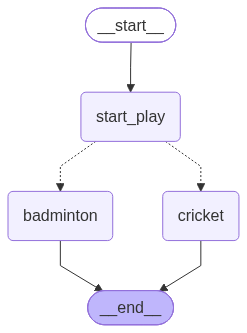

In [ ]:
from IPython.display import Image,display
from langgraph.graph import StateGraph,START,END

## Build Graph
graph=StateGraph(State)

## Adding the nodes
graph.add_node("start_play",start_play)
graph.add_node("cricket",cricket)
graph.add_node("badminton",badminton)

## Schedule the flow of the graph

graph.add_edge(START,"start_play")
graph.add_conditional_edges("start_play",random_play)
graph.add_edge("cricket",END)
graph.add_edge("badminton",END)

## Compile the graph
graph_builder=graph.compile()

## View
display(Image(graph_builder.get_graph().draw_mermaid_png()))

**GRAPH Invocation**

In [ ]:
graph_builder.invoke({"graph_info":"Hey My name is Alex"})

Start_Play node has been called
My badminton node has been called


{'graph_info': 'Hey My name is Alex I am planning to play Badminton'}

### ReAct Agent Architecture

#### Aim
This is the intuition behind ReAct, a general agent architecture.

1. act - let the model call specific tools
2. observe - pass the tool output back to the model
3. reason - let the model reason about the tool output to decide what to do next (e.g., call another tool or just respond directly)


In [ ]:
import os
from google.colab import userdata

os.environ["GOOGLE_API_KEY"]=userdata.get('gemini_key')
#genai.configure(api_key=userdata.get('gemini_key'))

from langchain_community.tools import ArxivQueryRun,WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper,ArxivAPIWrapper

In [ ]:
import os
from google.colab import userdata

# To enable tracing by Langsmith for compiled graphs
os.environ["LANGCHAIN_TRACING_V2"] = "true"
os.environ["LANGCHAIN_API_KEY"] = userdata.get('Langsmith_key')
os.environ["LANGCHAIN_PROJECT"] = "Academy_Langgraph"

In [ ]:
import os

!pip install wikipedia

api_wrapper_wiki=WikipediaAPIWrapper(top_k_results=1,doc_content_chars_max=500)
wiki=WikipediaQueryRun(api_wrapper=api_wrapper_wiki)
wiki.name

'wikipedia'

In [ ]:
#wiki.invoke("What is machine learning")

In [ ]:
### Custom Functions
def multiply(a: int, b: int) -> int:
    """Multiply a and b.

    Args:
        a: first int
        b: second int
    """
    return a * b

# This will be a tool
def add(a: int, b: int) -> int:
    """Adds a and b.

    Args:
        a: first int
        b: second int
    """
    return a + b

def divide(a: int, b: int) -> float:
    """Divide a and b.

    Args:
        a: first int
        b: second int
    """
    return a / b


In [ ]:
os.environ["TAVILY_API_KEY"]=userdata.get('tavily_key')

### Tavily Search Tool
from langchain_community.tools.tavily_search import TavilySearchResults

tavily = TavilySearchResults()

In [ ]:
tavily.invoke("Provide me the recent AI news for Sep 29 2026")

[{'title': 'AI News | Latest News | Insights Powering AI-Driven Business Growth',
  'url': 'https://www.artificialintelligence-news.com',
  'content': 'AI in Action\n\nOctober 6, 2026\n\n### How McDonald’s uses AI to recommend menu prices\n\nAI in Action\n\nSeptember 30, 2026\n\n### Meta Muse gains enterprise software connectors\n\nWorld of Work\n\nSeptember 29, 2026\n\n#### Deep Learning\n\n### Motional and MIT AI explains self-driving car decisions\n\nPhysical AI\n\nSeptember 2, 2026\n\n### Aviva deploys AI to stop £230M in sophisticated insurance fraud\n\nAI in Action\n\nJune 8, 2026\n\n### China’s AI just mapped its entire renewable energy grid. Here’s why the rest of the world should pay attention\n\nEnvironment & Sustainability\n\nMay 22, 2026\n\n## Subscribe\n\nAll our premium content and latest tech news delivered straight to your inbox\n\nSubscribe\n\n## Resources\n\nView All Resources\n\nWorld of Work\n\nSeptember 22, 2026 [...] Governance, Regulation & Policy\n\n# Meta warns

In [ ]:
### Combine all the tools in the list

tools=[tavily,add,divide,multiply,wiki]

In [ ]:
## Initialize my LLM model

from langchain_google_genai import ChatGoogleGenerativeAI

llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")

llm_with_tools=llm.bind_tools(tools)

In [ ]:
from pprint import pprint
from langchain_core.messages import AIMessage, HumanMessage
llm_with_tools.invoke([HumanMessage(content=f"What is the recent AI News as on 29 Sep 2026")])

AIMessage(content=[], additional_kwargs={'function_call': {'name': 'tavily_search_results_json', 'arguments': '{"query": "AI news September 2026"}'}, '__gemini_function_call_thought_signatures__': {'call_12033727410359920332': 'EmAKXgFpFH0TI2r4vj7APzUaqL4us14Dq2EaPAdJFOk4Aj7ccpBcuqfOqFz2wY0P7xFgwZGjTBEBQU6TPBunlg3uURS5uKd6lS/BHrvCcvRaCrsziG2emmpT4A3PgeGUw5A='}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.5-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1c9b3-c02d-703a-9071-f51fda62add5-0', tool_calls=[{'name': 'tavily_search_results_json', 'args': {'query': 'AI news September 2026'}, 'id': 'call_12033727410359920332', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 384, 'output_tokens': 29, 'total_tokens': 413, 'input_token_details': {'cache_read': 0}})

In [ ]:
#llm_with_tools.invoke([HumanMessage(content=f"What is the recent AI News")]).tool_calls
#llm_with_tools.invoke([HumanMessage(content=f"What is the theory of relativity")]).tool_calls
#llm_with_tools.invoke([HumanMessage(content=f"What is 2 plus 2?")]).tool_calls
#llm_with_tools.invoke([HumanMessage(content=f"top 2 articles on psychoanalysis")]).tool_calls

In [ ]:
## State Schema
from typing_extensions import TypedDict
from langchain_core.messages import AnyMessage
from typing import Annotated
from langgraph.graph.message import add_messages
class State(TypedDict):
    messages:Annotated[list[AnyMessage],add_messages]

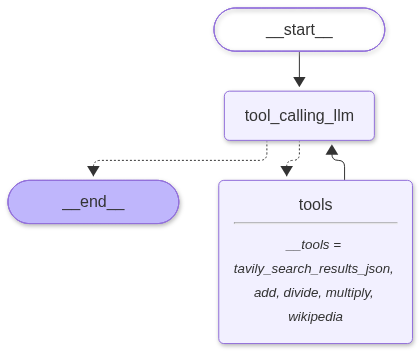

In [ ]:
### Entire Chatbot With LangGraph
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

### Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tools.invoke(state["messages"])]}

# Build graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition,
)
builder.add_edge("tools","tool_calling_llm")


graph = builder.compile()

# View
display(Image(graph.get_graph().draw_mermaid_png()))


In [ ]:
messages=graph.invoke({"messages":HumanMessage(content="Provide me the top 10 recent AI news for April 27 2026. Add 5 plus 5. Then multiply by 10. I also want to know about gravity and good articles on self attention")})
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

Provide me the top 10 recent AI news for April 27 2026. Add 5 plus 5. Then multiply by 10. I also want to know about gravity and good articles on self attention
================================== Ai Message ==================================

[]
Tool Calls:
  tavily_search_results_json (call_9954877470759482648)
 Call ID: call_9954877470759482648
  Args:
    query: AI news April 27 2026
  wikipedia (call_9954877470759484355)
 Call ID: call_9954877470759484355
  Args:
    query: Gravity
  tavily_search_results_json (call_9954877470759481966)
 Call ID: call_9954877470759481966
  Args:
    query: self attention mechanism transformer articles tutorial
  add (call_9954877470759483673)
 Call ID: call_9954877470759483673
  Args:
    b: 5
    a: 5
================================= Tool Message =================================
Name: tavily_search_results_json

[{"title": "AI Today - April 27th, 2026", "url": "htt

In [ ]:
messages=graph.invoke({"messages":HumanMessage(content="What is the latest news for 10 nov 2026? Also add 2 plus 4. then multiple by 3. ")})
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

What is the latest news for 10 nov 2026? Also add 2 plus 4. then multiple by 3. 
================================== Ai Message ==================================

[]
Tool Calls:
  add (call_1634696057852706338)
 Call ID: call_1634696057852706338
  Args:
    a: 2
    b: 4
================================= Tool Message =================================
Name: add

6
================================== Ai Message ==================================

[]
Tool Calls:
  multiply (call_13457154357756507116)
 Call ID: call_13457154357756507116
  Args:
    b: 3
    a: 6
================================= Tool Message =================================
Name: multiply

18
================================== Ai Message ==================================

[]
Tool Calls:
  tavily_search_results_json (call_3510318205413019463)
 Call ID: call_3510318205413019463
  Args:
    query: news November 10 2026
=========================

### Add Memory to Agents

In [ ]:
messages=graph.invoke({"messages":HumanMessage(content="What is 5 plus 8")})
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

What is 5 plus 8
================================== Ai Message ==================================

[]
Tool Calls:
  add (call_60504194841089803)
 Call ID: call_60504194841089803
  Args:
    a: 5
    b: 8
================================= Tool Message =================================
Name: add

13
================================== Ai Message ==================================

[{'type': 'text', 'text': '5 plus 8 is 13.', 'extras': {'signature': 'EmAKXgFpFH0TVHtdq0OO4F+6XZEI78ZzKimfgG0lxkLESelXt1RFAEyP73rVPE5RFJul27he4RXr23DCOFjk1zVuaBVDU5dlV8C+njoi/wGqzWBhxTQSt3sDiMP7PWjwnXs='}}]


In [ ]:
messages=[HumanMessage(content="Divide that by 5")]
messages=graph.invoke({"messages":messages})
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

Divide that by 5
================================== Ai Message ==================================

[{'type': 'text', 'text': "It looks like you want to divide a number by 5, but I'm not sure which number you are referring to! Could you please tell me what number you'd like to divide?", 'extras': {'signature': 'EmAKXgFpFH0TkFlH3OPD1gONYq6y59VX/oHnEuOn8kNYzOybafMCVUztfWvhaiamJX/igG5pUXc6p4fCGNhABiypRnybwWLd4SHvbtvPu0xEtx0djHodFuzpF6roGXQ3DMk='}}]


**MemorySaver**

LangGraph can use a checkpointer to automatically save the graph state after each step.

This built-in persistence layer gives us memory, allowing LangGraph to pick up from the last state update.

One of the easiest checkpointers to use is the MemorySaver, an in-memory key-value store for Graph state.

All we need to do is simply compile the graph with a checkpointer, and our graph has memory!

In [ ]:
### Entire Chatbot With LangGraph
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

### Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tools.invoke(state["messages"])]}

# Build graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition,
)
builder.add_edge("tools","tool_calling_llm")


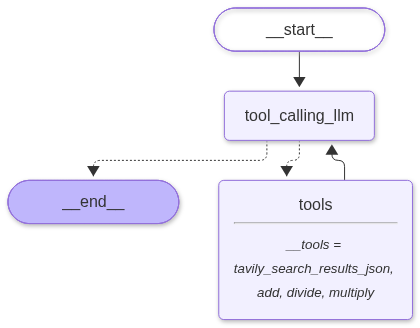

In [ ]:
from langgraph.checkpoint.memory import MemorySaver
memory=MemorySaver()
graph_memory = builder.compile(checkpointer=memory)

# View
display(Image(graph_memory.get_graph().draw_mermaid_png()))

In [ ]:
## Specify the thread

config={"configurable":{"thread_id":"1"}}
# Specify an input
messages = [HumanMessage(content="Add 12 and 13.")]
messages=graph_memory.invoke({"messages":messages},config=config)
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

Add 12 and 13.
================================== Ai Message ==================================

[]
Tool Calls:
  add (call_5490452992132911606)
 Call ID: call_5490452992132911606
  Args:
    b: 13
    a: 12
================================= Tool Message =================================
Name: add

25
================================== Ai Message ==================================

[{'type': 'text', 'text': '12 + 13 = 25', 'extras': {'signature': 'EmAKXgFpFH0T7LlaoCFp1bdsWIYiPNjnTJuRKZjDf9ftYcSk4ixax5f7aRF0a7jj+eXRluNei4Ips3wUJzEVogDw5i+YVG5gtlo56Os9iPZ4RsdvxZ+pmyxAijz1bejAZB0='}}]


In [ ]:
messages = [HumanMessage(content="add that number to 25")]
messages=graph_memory.invoke({"messages":messages},config=config)
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

Add 12 and 13.
================================== Ai Message ==================================

[]
Tool Calls:
  add (call_5490452992132911606)
 Call ID: call_5490452992132911606
  Args:
    b: 13
    a: 12
================================= Tool Message =================================
Name: add

25
================================== Ai Message ==================================

[{'type': 'text', 'text': '12 + 13 = 25', 'extras': {'signature': 'EmAKXgFpFH0T7LlaoCFp1bdsWIYiPNjnTJuRKZjDf9ftYcSk4ixax5f7aRF0a7jj+eXRluNei4Ips3wUJzEVogDw5i+YVG5gtlo56Os9iPZ4RsdvxZ+pmyxAijz1bejAZB0='}}]
================================ Human Message =================================

add that number to 25
================================== Ai Message ==================================

[]
Tool Calls:
  add (call_10690819840912803863)
 Call ID: call_10690819840912803863
  Args:
    a: 25
    b: 25
==============================

In [ ]:
messages = [HumanMessage(content="then multiplty that number by 2")]
messages=graph_memory.invoke({"messages":messages},config=config)
for m in messages['messages']:
    m.pretty_print()

================================ Human Message =================================

Add 12 and 13.
================================== Ai Message ==================================

[]
Tool Calls:
  add (call_5490452992132911606)
 Call ID: call_5490452992132911606
  Args:
    b: 13
    a: 12
================================= Tool Message =================================
Name: add

25
================================== Ai Message ==================================

[{'type': 'text', 'text': '12 + 13 = 25', 'extras': {'signature': 'EmAKXgFpFH0T7LlaoCFp1bdsWIYiPNjnTJuRKZjDf9ftYcSk4ixax5f7aRF0a7jj+eXRluNei4Ips3wUJzEVogDw5i+YVG5gtlo56Os9iPZ4RsdvxZ+pmyxAijz1bejAZB0='}}]
================================ Human Message =================================

add that number to 25
================================== Ai Message ==================================

[]
Tool Calls:
  add (call_10690819840912803863)
 Call ID: call_10690819840912803863
  Args:
    a: 25
    b: 25
==============================